<a href="https://colab.research.google.com/github/anasabrinars/Fase-1-FIAP/blob/main/Oportunidades_e_Recomenda%C3%A7%C3%A3o.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [63]:
#imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [64]:
#bases

df_customers = pd.read_csv('/content/olist_customers_dataset.csv')
df_geolocation = pd.read_csv('/content/olist_geolocation_dataset.csv')
df_order_items = pd.read_csv('/content/olist_order_items_dataset.csv')
df_orders = pd.read_csv('/content/olist_orders_dataset.csv')
df_sellers = pd.read_csv('/content/olist_sellers_dataset.csv')

In [65]:
# trocando os nomes das colunas

df_customers = df_customers.rename(columns={
    'customer_zip_code_prefix': 'zip_code_prefix',
    'customer_city': 'cidade',
    'customer_state': 'estado'
})

df_sellers = df_sellers.rename(columns={
    'seller_zip_code_prefix': 'zip_code_prefix',
    'seller_city': 'cidade',
    'seller_state': 'estado'
})

In [66]:
# Relacionar pedidos com clientes
df_frete = df_orders.merge(
    df_customers[['customer_id', 'zip_code_prefix',
                  'cidade', 'estado']],
    on='customer_id',
    how='left'
)

# Relacionar pedidos com produtos e vendedores
df_frete = df_frete.merge(
    df_order_items[['order_id', 'seller_id',
                    'freight_value', 'price']],
    on='order_id',
    how='inner'
)

# Adicionar informações dos vendedores
df_frete = df_frete.merge(
    df_sellers[['seller_id', 'zip_code_prefix',
                'cidade', 'estado']],
    on='seller_id',
    how='left',
    suffixes=('_cliente', '_vendedor')
)

# Renomear colunas para facilitar a leitura
df_frete = df_frete.rename(columns={
    'cidade_cliente': 'cidade_destino',
    'estado_cliente': 'estado_destino',
    'cidade_vendedor': 'cidade_origem',
    'estado_vendedor': 'estado_origem',
    'zip_code_prefix_cliente': 'cep_destino',
    'zip_code_prefix_vendedor': 'cep_origem'
})

df_frete.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,cep_destino,cidade_destino,estado_destino,seller_id,freight_value,price,cep_origem,cidade_origem,estado_origem
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,3149,sao paulo,SP,3504c0cb71d7fa48d967e0e4c94d59d9,8.72,29.99,9350,maua,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,47813,barreiras,BA,289cdb325fb7e7f891c38608bf9e0962,22.76,118.70,31570,belo horizonte,SP
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,75265,vianopolis,GO,4869f7a5dfa277a7dca6462dcf3b52b2,19.22,159.90,14840,guariba,SP
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,59296,sao goncalo do amarante,RN,66922902710d126a0e7d26b0e3805106,27.20,45.00,31842,belo horizonte,MG
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,9195,santo andre,SP,2c9e548be18521d1c43cde1c582c6de8,8.72,19.90,8752,mogi das cruzes,SP


In [67]:
frete_estado = (
    df_frete.groupby('estado_destino')
    .agg(
        frete_medio=('freight_value', 'mean'),
        frete_total=('freight_value', 'sum'),
        quantidade=('order_id', 'count')
    )
    .reset_index()
)

frete_estado = frete_estado.sort_values(
    'frete_medio',
    ascending=False
)

frete_estado.head(10)

,estado_destino,frete_medio,frete_total,quantidade
21,RR,42.984423,2235.19,52
14,PB,42.723804,25719.73,602
20,RO,41.069712,11417.38,278
0,AC,40.073370,3686.75,92
16,PI,39.147970,21218.20,542
9,MA,38.257002,31523.77,824
26,TO,37.246603,11732.68,315
24,SE,36.653169,14111.47,385
1,AL,35.843671,15914.59,444
13,PA,35.832685,38699.30,1080


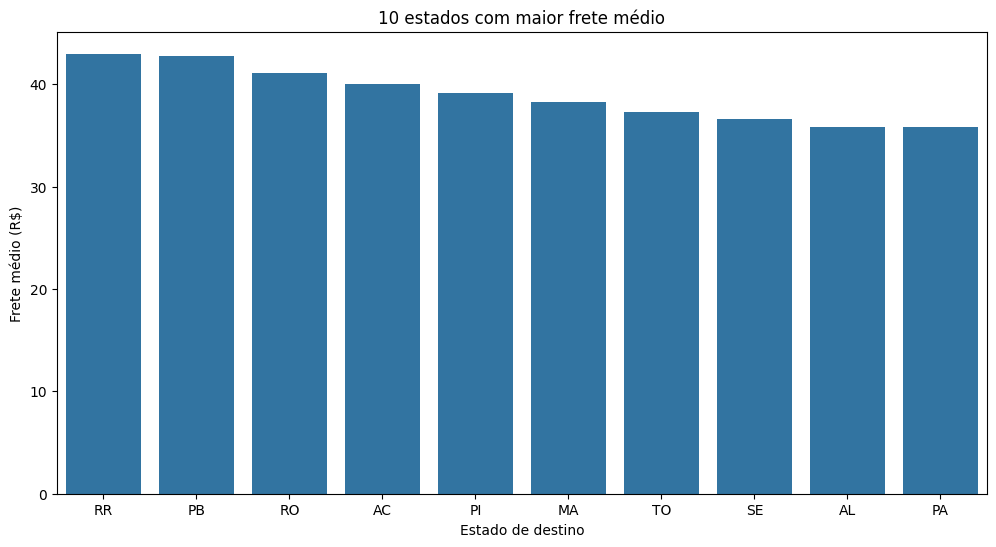

In [68]:
# visualização gráfico

plt.figure(figsize=(12, 6))

sns.barplot(
    data=frete_estado.head(10),
    x='estado_destino',
    y='frete_medio'
)

plt.title('10 estados com maior frete médio')
plt.xlabel('Estado de destino')
plt.ylabel('Frete médio (R$)')
plt.show()

In [69]:
rotas = (
    df_frete.groupby([
        'estado_origem',
        'cidade_origem',
        'estado_destino',
        'cidade_destino'
    ])
    .agg(
        frete_medio=('freight_value', 'mean'),
        frete_total=('freight_value', 'sum'),
        quantidade_pedidos=('order_id', 'nunique'),
        valor_produto_medio=('price', 'mean')
    )
    .reset_index()
)

# Considerar apenas rotas com volume relevante
rotas = rotas[
    rotas['quantidade_pedidos'] >= 10
]

rotas = rotas.sort_values(
    'frete_medio',
    ascending=False
)

rotas.head(10)

,estado_origem,cidade_origem,estado_destino,cidade_destino,frete_medio,frete_total,quantidade_pedidos,valor_produto_medio
11138,RS,cachoeirinha,RJ,rio de janeiro,67.584615,878.60,13,278.838462
35077,SP,sorocaba,DF,brasilia,57.260833,687.13,11,314.110000
33272,SP,sao paulo,PB,campina grande,51.855625,829.69,16,319.285000
21951,SP,itaquaquecetuba,CE,fortaleza,50.449286,706.29,10,175.030714
11360,RS,caxias do sul,RJ,rio de janeiro,49.713077,646.27,13,361.029231
3786,MG,ilicinea,RJ,nova iguacu,49.654545,546.20,10,129.541818
20366,SP,ibitinga,MA,sao luis,48.077500,576.93,11,131.063333
11428,RS,caxias do sul,SP,sao paulo,47.797273,1577.31,30,228.743939
3879,MG,ilicinea,SP,sao paulo,46.906667,1266.48,24,130.549630
3601,MG,ilicinea,BA,salvador,46.638148,1259.23,23,116.771111


In [70]:
df_geolocation = df_geolocation.rename(columns={
    'geolocation_zip_code_prefix': 'zip_code_prefix',
    'geolocation_lat': 'latitude',
    'geolocation_lng': 'longitude',
    'geolocation_city': 'cidade',
    'geolocation_state': 'estado'
})

In [71]:
geo = (
    df_geolocation.groupby('zip_code_prefix')
    .agg(
        latitude=('latitude', 'mean'),
        longitude=('longitude', 'mean')
    )
    .reset_index()
)

# Coordenadas do cliente
geo_cliente = geo.rename(columns={
    'zip_code_prefix': 'cep_destino',
    'latitude': 'lat_destino',
    'longitude': 'lon_destino'
})

# Coordenadas do vendedor
geo_vendedor = geo.rename(columns={
    'zip_code_prefix': 'cep_origem',
    'latitude': 'lat_origem',
    'longitude': 'lon_origem'
})

df_frete = df_frete.merge(
    geo_cliente,
    on='cep_destino',
    how='left'
)

df_frete = df_frete.merge(
    geo_vendedor,
    on='cep_origem',
    how='left'
)

In [72]:
def calcular_distancia(lat1, lon1, lat2, lon2):

    R = 6371

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2)**2 +
        np.cos(lat1) * np.cos(lat2) *
        np.sin(dlon / 2)**2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c

df_frete['distancia_km'] = calcular_distancia(
    df_frete['lat_origem'],
    df_frete['lon_origem'],
    df_frete['lat_destino'],
    df_frete['lon_destino']
)

In [73]:
df_frete['order_purchase_timestamp'] = pd.to_datetime(
    df_frete['order_purchase_timestamp']
)

df_frete['order_delivered_customer_date'] = pd.to_datetime(
    df_frete['order_delivered_customer_date']
)

df_frete['tempo_entrega'] = (
    df_frete['order_delivered_customer_date'] -
    df_frete['order_purchase_timestamp']
).dt.days

In [74]:
rotas_criticas = (
    df_frete.groupby([
        'estado_origem',
        'estado_destino'
    ])
    .agg(
        frete_medio=('freight_value', 'mean'),
        distancia_media=('distancia_km', 'mean'),
        entrega_media=('tempo_entrega', 'mean'),
        quantidade_pedidos=('order_id', 'nunique')
    )
    .reset_index()
)

rotas_criticas = rotas_criticas[
    rotas_criticas['quantidade_pedidos'] >= 10
]

rotas_criticas.sort_values(
    'frete_medio',
    ascending=False
).head(15)

,estado_origem,estado_destino,frete_medio,distancia_media,entrega_media,quantidade_pedidos
370,SC,PB,72.474000,2670.472816,25.850000,19
361,SC,CE,70.284348,2774.878530,27.409091,23
273,PR,PI,61.359063,2288.793497,17.300000,27
369,SC,PA,59.944286,2714.410947,23.190476,19
47,CE,RJ,59.746000,2181.912017,16.800000,10
345,RS,PE,59.198333,2902.908295,21.222222,17
219,PB,RJ,56.676000,1952.910109,14.222222,10
372,SC,PI,54.932105,2518.044850,21.631579,19
142,MA,RS,54.442353,3137.699693,18.588235,17
375,SC,RN,54.174286,2754.551199,18.857143,14


In [75]:
mediana_frete = rotas_criticas['frete_medio'].median()
mediana_entrega = rotas_criticas['entrega_media'].median()

rotas_criticas['classificacao'] = np.select(
    [
        (rotas_criticas['frete_medio'] > mediana_frete) &
        (rotas_criticas['entrega_media'] > mediana_entrega),

        (rotas_criticas['frete_medio'] > mediana_frete) &
        (rotas_criticas['entrega_media'] <= mediana_entrega),

        (rotas_criticas['frete_medio'] <= mediana_frete) &
        (rotas_criticas['entrega_media'] > mediana_entrega)
    ],
    [
        'Rota crítica',
        'Custo elevado',
        'Problema logístico'
    ],
    default='Rota eficiente'
)

rotas_criticas.head()

,estado_origem,estado_destino,frete_medio,distancia_media,entrega_media,quantidade_pedidos,classificacao
8,BA,BA,16.646538,206.888033,10.662162,70,Rota eficiente
9,BA,CE,31.473571,1010.146269,15.000000,14,Custo elevado
10,BA,DF,24.803158,1076.900261,11.055556,17,Rota eficiente
11,BA,ES,21.753846,824.336261,13.230769,11,Rota eficiente
13,BA,MA,30.736471,1237.645484,24.588235,16,Problema logístico


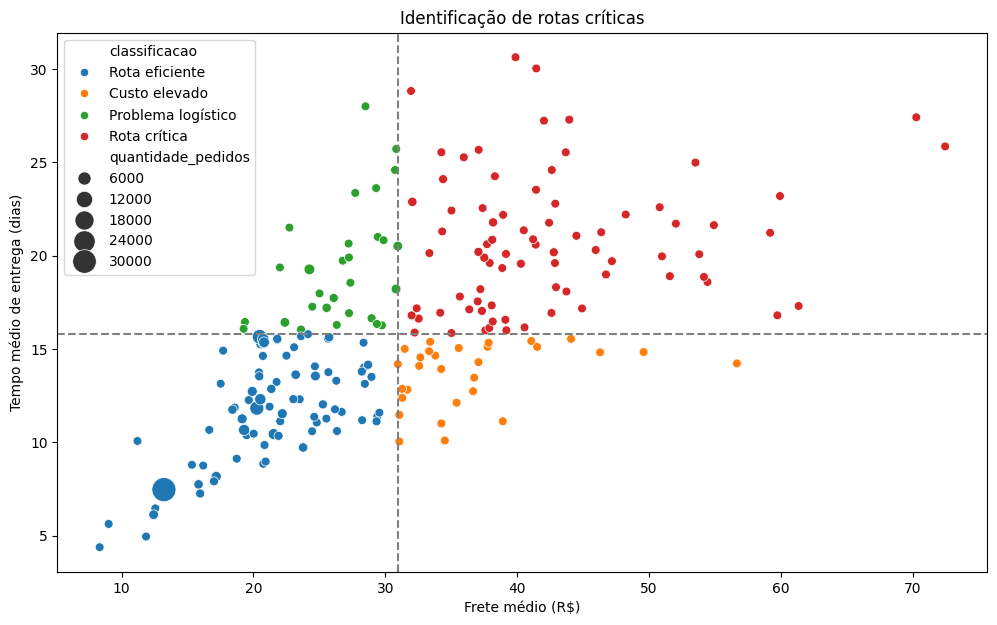

In [76]:
# visualização gráfico

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=rotas_criticas,
    x='frete_medio',
    y='entrega_media',
    hue='classificacao',
    size='quantidade_pedidos',
    sizes=(40, 300)
)

plt.axvline(mediana_frete, linestyle='--', color='gray')
plt.axhline(mediana_entrega, linestyle='--', color='gray')

plt.title('Identificação de rotas críticas')
plt.xlabel('Frete médio (R$)')
plt.ylabel('Tempo médio de entrega (dias)')

plt.show()

In [77]:
df_frete['frete_por_km'] = (
    df_frete['freight_value'] /
    df_frete['distancia_km'].replace(0, np.nan)
)

In [78]:
# bases

df_products = pd.read_csv('/content/olist_products_dataset.csv')
df_payments = pd.read_csv('/content/olist_order_payments_dataset.csv')
df_category = pd.read_csv('/content/product_category_name_translation.csv')

In [79]:
# Relacionar pedidos com clientes
df_pricing = df_orders.merge(
    df_customers[['customer_id', 'estado', 'cidade']],
    on='customer_id',
    how='left'
)

# Relacionar pedidos com itens
df_pricing = df_pricing.merge(
    df_order_items[['order_id', 'product_id',
                    'price', 'freight_value']],
    on='order_id',
    how='inner'
)

# Relacionar com categorias
df_pricing = df_pricing.merge(
    df_products[['product_id', 'product_category_name']],
    on='product_id',
    how='left'
)

df_pricing.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,estado,cidade,product_id,price,freight_value,product_category_name
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,SP,sao paulo,87285b34884572647811a353c7ac498a,29.99,8.72,utilidades_domesticas
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,BA,barreiras,595fac2a385ac33a80bd5114aec74eb8,118.70,22.76,perfumaria
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,GO,vianopolis,aa4383b373c6aca5d8797843e5594415,159.90,19.22,automotivo
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,RN,sao goncalo do amarante,d0b61bfb1de832b15ba9d266ca96e5b0,45.00,27.20,pet_shop
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,SP,santo andre,65266b2da20d04dbe00c5c2d3bb7859e,19.90,8.72,papelaria


In [80]:
pricing_categoria = (
    df_pricing.groupby('product_category_name')
    .agg(
        faturamento=('price', 'sum'),
        preco_medio=('price', 'mean'),
        quantidade_vendida=('product_id', 'count'),
        frete_medio=('freight_value', 'mean')
    )
    .reset_index()
)

pricing_categoria = pricing_categoria.sort_values(
    'faturamento',
    ascending=False
)

pricing_categoria.head(10)

,product_category_name,faturamento,preco_medio,quantidade_vendida,frete_medio
11,beleza_saude,1258681.34,130.163531,9670,18.879703
66,relogios_presentes,1205005.68,201.135984,5991,16.781160
13,cama_mesa_banho,1036988.68,93.296327,11115,18.415928
32,esporte_lazer,988048.97,114.344285,8641,19.512500
44,informatica_acessorios,911954.32,116.513903,7827,18.821781
54,moveis_decoracao,729762.49,87.564494,8334,20.728258
26,cool_stuff,635290.85,167.357969,3796,22.138857
72,utilidades_domesticas,632248.66,90.788148,6964,20.986374
8,automotivo,592720.11,139.957523,4235,21.880569
40,ferramentas_jardim,485256.46,111.630196,4347,22.765758


In [81]:
pricing_regiao = (
    df_pricing.groupby([
        'estado',
        'product_category_name'
    ])
    .agg(
        faturamento=('price', 'sum'),
        preco_medio=('price', 'mean'),
        quantidade_vendida=('product_id', 'count'),
        frete_medio=('freight_value', 'mean')
    )
    .reset_index()
)

pricing_regiao.head(10)

,estado,product_category_name,faturamento,preco_medio,quantidade_vendida,frete_medio
0,AC,artigos_de_natal,69.90,69.900000,1,60.950000
1,AC,automotivo,540.98,135.245000,4,30.232500
2,AC,bebes,697.84,232.613333,3,58.043333
3,AC,beleza_saude,1386.58,198.082857,7,38.345714
4,AC,brinquedos,234.79,78.263333,3,27.753333
5,AC,cama_mesa_banho,567.70,141.925000,4,39.377500
6,AC,consoles_games,276.14,276.140000,1,45.780000
7,AC,cool_stuff,99.99,99.990000,1,30.230000
8,AC,eletronicos,487.55,121.887500,4,44.782500
9,AC,eletroportateis,54.00,54.000000,1,46.910000


In [82]:
ranking_regiao = pricing_regiao.sort_values(
    ['estado', 'faturamento'],
    ascending=[True, False]
)

ranking_regiao.groupby('estado').head(5)

,estado,product_category_name,faturamento,preco_medio,quantidade_vendida,frete_medio
10,AC,esporte_lazer,1677.46,186.384444,9,43.786667
24,AC,relogios_presentes,1389.60,347.400000,4,46.030000
3,AC,beleza_saude,1386.58,198.082857,7,38.345714
19,AC,moveis_decoracao,1316.44,109.703333,12,35.855000
14,AC,informatica_acessorios,1290.48,143.386667,9,32.230000
...,...,...,...,...,...,...
1364,TO,relogios_presentes,5446.89,181.563000,30,31.667333
1344,TO,esporte_lazer,5144.32,205.772800,25,52.399600
1333,TO,beleza_saude,4798.99,133.305278,36,34.092778
1349,TO,informatica_acessorios,4360.97,207.665238,21,33.337143


In [83]:
from itertools import combinations
from collections import Counter

# Separar categorias por pedido
df_cross = df_pricing[
    ['order_id', 'product_category_name']
].dropna()

# Remover categorias repetidas dentro do mesmo pedido
categorias_pedido = (
    df_cross.groupby('order_id')['product_category_name']
    .apply(lambda x: sorted(set(x)))
)

# Contar combinações de categorias
contador_pares = Counter()

for categorias in categorias_pedido:
    pares = combinations(categorias, 2)
    contador_pares.update(pares)

# Criar DataFrame
df_pares = pd.DataFrame(
    contador_pares.items(),
    columns=['categorias_compradas_juntas', 'quantidade_pedidos']
)

df_pares = df_pares.sort_values(
    'quantidade_pedidos',
    ascending=False
)

df_pares.head(15)

,categorias_compradas_juntas,quantidade_pedidos
22,"(cama_mesa_banho, moveis_decoracao)",70
80,"(cama_mesa_banho, casa_conforto)",43
27,"(moveis_decoracao, utilidades_domesticas)",24
9,"(bebes, cool_stuff)",20
3,"(cama_mesa_banho, utilidades_domesticas)",20
1,"(bebes, brinquedos)",19
42,"(ferramentas_jardim, moveis_decoracao)",17
44,"(bebes, cama_mesa_banho)",17
74,"(beleza_saude, esporte_lazer)",14
21,"(casa_construcao, moveis_decoracao)",13


In [84]:
# Criar pares de categorias por pedido e estado
df_cross_regiao = df_pricing[
    ['order_id', 'estado', 'product_category_name']
].dropna()

df_cross_regiao = df_cross_regiao.drop_duplicates()

contador_regional = Counter()

for (estado, pedido), grupo in df_cross_regiao.groupby(
    ['estado', 'order_id']
):
    categorias = sorted(set(grupo['product_category_name']))

    for par in combinations(categorias, 2):
        contador_regional[(estado, par)] += 1

# Transformar em DataFrame
df_cross_resultado = pd.DataFrame(
    [
        {
            'estado': estado,
            'categoria_1': par[0],
            'categoria_2': par[1],
            'quantidade_pedidos': quantidade
        }
        for (estado, par), quantidade in contador_regional.items()
    ]
)

df_cross_resultado = df_cross_resultado.sort_values(
    'quantidade_pedidos',
    ascending=False
)

df_cross_resultado.head(20)

,estado,categoria_1,categoria_2,quantidade_pedidos
324,SP,cama_mesa_banho,moveis_decoracao,25
372,SP,cama_mesa_banho,casa_conforto,17
313,SP,cama_mesa_banho,utilidades_domesticas,14
199,RJ,cama_mesa_banho,moveis_decoracao,13
326,SP,moveis_decoracao,utilidades_domesticas,10
312,SP,bebes,brinquedos,10
67,MG,cama_mesa_banho,moveis_decoracao,9
350,SP,beleza_saude,esporte_lazer,8
203,RJ,cama_mesa_banho,casa_conforto,8
367,SP,bebes,moveis_decoracao,7


In [85]:
# Somar os produtos por pedido
ticket_pedido = (
    df_pricing.groupby(['order_id', 'estado'])
    .agg(
        valor_pedido=('price', 'sum'),
        quantidade_itens=('product_id', 'count')
    )
    .reset_index()
)

# Ticket médio por estado
ticket_regiao = (
    ticket_pedido.groupby('estado')
    .agg(
        ticket_medio=('valor_pedido', 'mean'),
        quantidade_pedidos=('order_id', 'nunique'),
        itens_por_pedido=('quantidade_itens', 'mean')
    )
    .reset_index()
)

ticket_regiao = ticket_regiao.sort_values(
    'ticket_medio',
    ascending=False
)

ticket_regiao.head(15)

,estado,ticket_medio,quantidade_pedidos,itens_por_pedido
14,PB,216.669323,532,1.131579
3,AP,198.151471,68,1.205882
0,AC,197.320370,81,1.135802
1,AL,195.413163,411,1.080292
20,RO,186.804211,247,1.125506
13,PA,184.482278,970,1.113402
26,TO,177.855699,279,1.129032
16,PI,176.296308,493,1.099391
12,MT,173.259723,903,1.168328
19,RN,172.271743,482,1.097510


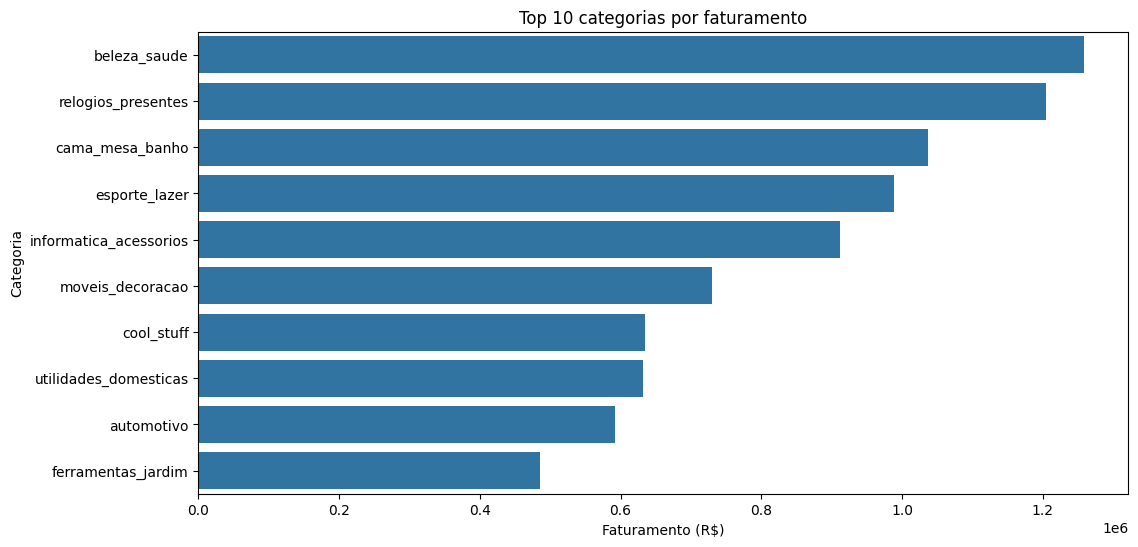

In [86]:
# visualização gráfico

top_categorias = pricing_categoria.nlargest(
    10, 'faturamento'
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_categorias,
    x='faturamento',
    y='product_category_name'
)

plt.title('Top 10 categorias por faturamento')
plt.xlabel('Faturamento (R$)')
plt.ylabel('Categoria')

plt.show()

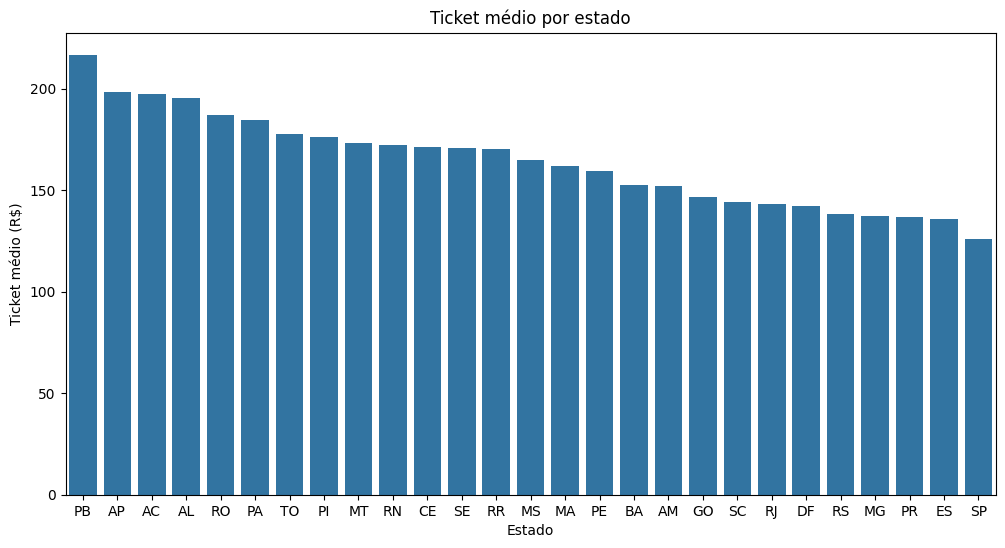

In [87]:
# visualização gráfico

plt.figure(figsize=(12, 6))

sns.barplot(
    data=ticket_regiao.sort_values(
        'ticket_medio', ascending=False
    ),
    x='estado',
    y='ticket_medio'
)

plt.title('Ticket médio por estado')
plt.xlabel('Estado')
plt.ylabel('Ticket médio (R$)')

plt.show()

In [88]:
# bases

df_review = pd.read_csv('/content/olist_order_reviews_dataset.csv')

In [92]:
# Relacionar pedidos com itens
df_sellers_analise = df_order_items[
    ['order_id', 'seller_id']
].merge(
    df_orders[
        ['order_id',
         'order_purchase_timestamp',
         'order_delivered_customer_date',
         'order_status']
    ],
    on='order_id',
    how='inner'
)

# Relacionar com avaliações
df_sellers_analise = df_sellers_analise.merge(
    df_review[
        ['order_id', 'review_score']
    ],
    on='order_id',
    how='left'
)

# Relacionar com informações dos vendedores
df_sellers_analise = df_sellers_analise.merge(
    df_sellers[
        ['seller_id', 'cidade', 'estado']
    ],
    on='seller_id',
    how='left'
)

df_sellers_analise.head()

,order_id,seller_id,order_purchase_timestamp,order_delivered_customer_date,order_status,review_score,cidade,estado
0,00010242fe8c5a6d1ba2dd792cb16214,48436dade18ac8b2bce089ec2a041202,2017-09-13 08:59:02,2017-09-20 23:43:48,delivered,5.0,volta redonda,SP
1,00018f77f2f0320c557190d7a144bdd3,dd7ddc04e1b6c2c614352b383efe2d36,2017-04-26 10:53:06,2017-05-12 16:04:24,delivered,4.0,sao paulo,SP
2,000229ec398224ef6ca0657da4fc703e,5b51032eddd242adc84c38acab88f23d,2018-01-14 14:33:31,2018-01-22 13:19:16,delivered,5.0,borda da mata,MG
3,00024acbcdf0a6daa1e931b038114c75,9d7a1d34a5052409006425275ba1c2b4,2018-08-08 10:00:35,2018-08-14 13:32:39,delivered,4.0,franca,SP
4,00042b26cf59d7ce69dfabb4e55b4fd9,df560393f3a51e74553ab94004ba5c87,2017-02-04 13:57:51,2017-03-01 16:42:31,delivered,5.0,loanda,PR


In [93]:
df_sellers_analise[
    'order_purchase_timestamp'
] = pd.to_datetime(
    df_sellers_analise['order_purchase_timestamp']
)

df_sellers_analise[
    'order_delivered_customer_date'
] = pd.to_datetime(
    df_sellers_analise['order_delivered_customer_date']
)

df_sellers_analise['tempo_entrega'] = (
    df_sellers_analise['order_delivered_customer_date'] -
    df_sellers_analise['order_purchase_timestamp']
).dt.total_seconds() / 86400

In [94]:
df_sellers_analise = df_sellers_analise[
    (df_sellers_analise['order_status'] == 'delivered') &
    (df_sellers_analise['tempo_entrega'].notna()) &
    (df_sellers_analise['review_score'].notna())
].copy()

In [95]:
# Uma linha por pedido e vendedor
df_sellers_analise = df_sellers_analise.drop_duplicates(
    subset=['order_id', 'seller_id']
)

# Consolidar indicadores por vendedor
ranking_sellers = (
    df_sellers_analise.groupby(
        ['seller_id', 'cidade', 'estado']
    )
    .agg(
        nota_media=('review_score', 'mean'),
        tempo_medio_entrega=('tempo_entrega', 'mean'),
        total_pedidos=('order_id', 'nunique'),
        avaliacoes_positivas=(
            'review_score',
            lambda x: (x >= 4).mean() * 100
        )
    )
    .reset_index()
)

ranking_sellers.head()

,seller_id,cidade,estado,nota_media,tempo_medio_entrega,total_pedidos,avaliacoes_positivas
0,0015a82c2db000af6aaaf3ae2ecb0532,santo andre,SP,3.666667,10.793885,3,66.666667
1,001cca7ae9ae17fb1caed9dfb1094831,cariacica,ES,4.062500,13.118734,192,76.041667
2,002100f778ceb8431b7a1020ff7ab48f,franca,SP,3.960000,16.386809,50,68.000000
3,003554e2dce176b5555353e4f3555ac8,goiania,GO,5.000000,4.646806,1,100.000000
4,004c9cd9d87a3c30c522c48c4fc07416,ibitinga,SP,4.136364,14.724615,154,75.974026


In [96]:
# Considerar apenas sellers com volume relevante
ranking_sellers = ranking_sellers[
    ranking_sellers['total_pedidos'] >= 10
].copy()

# Calcular medianas
mediana_nota = ranking_sellers['nota_media'].median()

mediana_entrega = ranking_sellers[
    'tempo_medio_entrega'
].median()

# Classificar vendedores
ranking_sellers['classificacao'] = np.select(
    [
        (ranking_sellers['nota_media'] >= mediana_nota) &
        (ranking_sellers['tempo_medio_entrega'] <= mediana_entrega),

        (ranking_sellers['nota_media'] >= mediana_nota) &
        (ranking_sellers['tempo_medio_entrega'] > mediana_entrega),

        (ranking_sellers['nota_media'] < mediana_nota) &
        (ranking_sellers['tempo_medio_entrega'] <= mediana_entrega)
    ],
    [
        'Alta satisfação e entrega rápida',
        'Alta satisfação e entrega lenta',
        'Baixa satisfação e entrega rápida'
    ],
    default='Baixa satisfação e entrega lenta'
)

In [97]:
# Percentil de satisfação: quanto maior, melhor
ranking_sellers['score_satisfacao'] = (
    ranking_sellers['nota_media'].rank(pct=True)
)

# Percentil de entrega: quanto menor o tempo, melhor
ranking_sellers['score_entrega'] = (
    ranking_sellers['tempo_medio_entrega']
    .rank(pct=True, ascending=False)
)

# Score final com pesos iguais
ranking_sellers['score_final'] = (
    ranking_sellers['score_satisfacao'] * 0.5 +
    ranking_sellers['score_entrega'] * 0.5
)

# Ranking final
ranking_sellers = ranking_sellers.sort_values(
    'score_final',
    ascending=False
)

ranking_sellers[
    [
        'seller_id',
        'cidade',
        'estado',
        'nota_media',
        'tempo_medio_entrega',
        'total_pedidos',
        'avaliacoes_positivas',
        'score_final',
        'classificacao'
    ]
].head(10)

,seller_id,cidade,estado,nota_media,tempo_medio_entrega,total_pedidos,avaliacoes_positivas,score_final,classificacao
762,41c2bad7229b0c25e6becf179ebf63ff,natal,RN,4.950000,4.693480,20,100.000000,0.997571,Alta satisfação e entrega rápida
562,30a81d8cf85fb2ada1b1b094c9583a95,sao paulo,SP,4.823529,4.290116,17,100.000000,0.992915,Alta satisfação e entrega rápida
2430,d13e50eaa47b4cbe9eb81465865d8cfc,santo andre,SP,4.818182,5.039004,66,96.969697,0.988866,Alta satisfação e entrega rápida
1976,aac51c486b672a9850d59f3e84b1cf88,sao paulo,SP,4.800000,4.651243,10,100.000000,0.987652,Alta satisfação e entrega rápida
997,54583ab379489add547fe47b628db589,sao bernardo do campo,SP,4.800000,5.116539,10,100.000000,0.984413,Alta satisfação e entrega rápida
2465,d4910f1cdcfdabd48d6b316e395d4a23,santo andre,SP,4.909091,6.125251,11,100.000000,0.983198,Alta satisfação e entrega rápida
547,2f4b0d3b9634b647d4edee577d7ebb7e,sao paulo,SP,4.900000,6.147946,10,100.000000,0.981174,Alta satisfação e entrega rápida
1064,5a6a02f419701fc8c605af71d4fc57a4,americana,SP,4.800000,5.593672,10,100.000000,0.980364,Alta satisfação e entrega rápida
2422,cfd7ddab722b902f7ac5b5f3ba6d723d,contagem,MG,4.750000,5.445188,12,91.666667,0.975911,Alta satisfação e entrega rápida
2081,b494891378bd8f4560abe576c52deacd,sao paulo,SP,4.736842,5.474568,19,94.736842,0.973684,Alta satisfação e entrega rápida


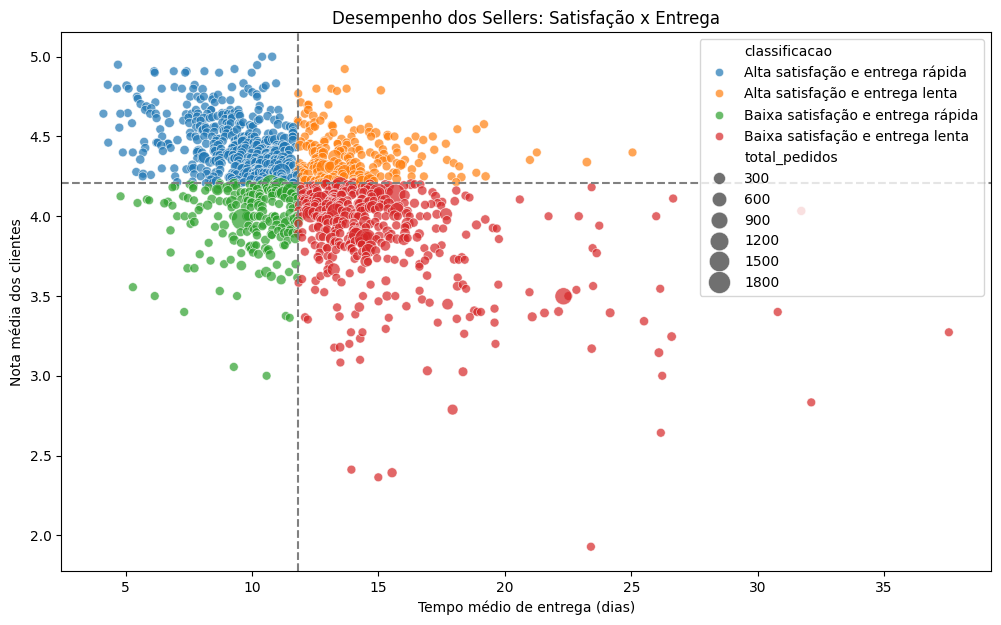

In [98]:
# visualização gráfico

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=ranking_sellers,
    x='tempo_medio_entrega',
    y='nota_media',
    hue='classificacao',
    size='total_pedidos',
    sizes=(40, 250),
    alpha=0.7
)

plt.axvline(mediana_entrega, linestyle='--', color='gray')
plt.axhline(mediana_nota, linestyle='--', color='gray')

plt.title('Desempenho dos Sellers: Satisfação x Entrega')
plt.xlabel('Tempo médio de entrega (dias)')
plt.ylabel('Nota média dos clientes')

plt.show()

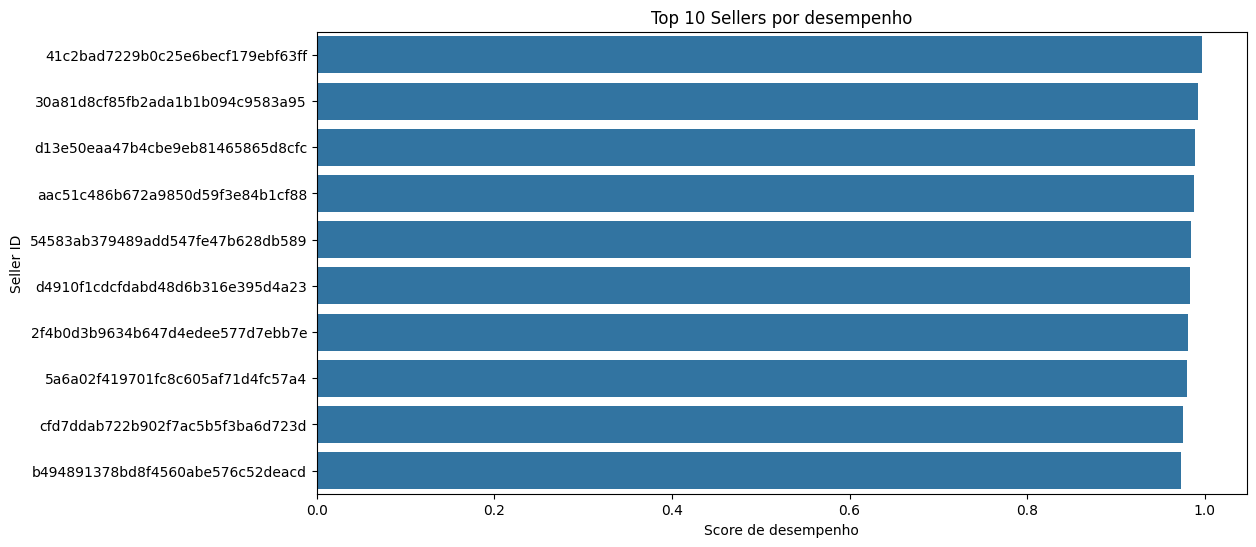

In [99]:
# visualização gráfico top 10

top_sellers = ranking_sellers.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_sellers,
    x='score_final',
    y='seller_id'
)

plt.title('Top 10 Sellers por desempenho')
plt.xlabel('Score de desempenho')
plt.ylabel('Seller ID')

plt.show()